# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [4]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [5]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [6]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

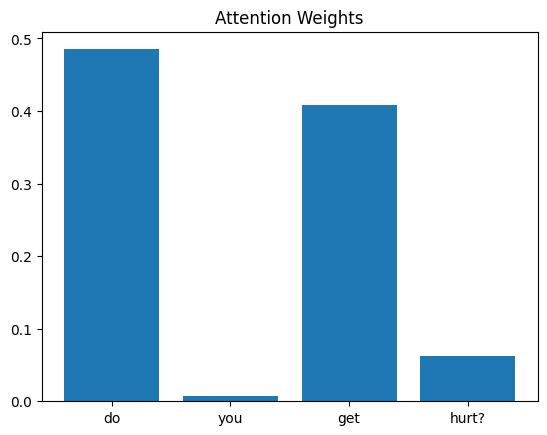

In [8]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

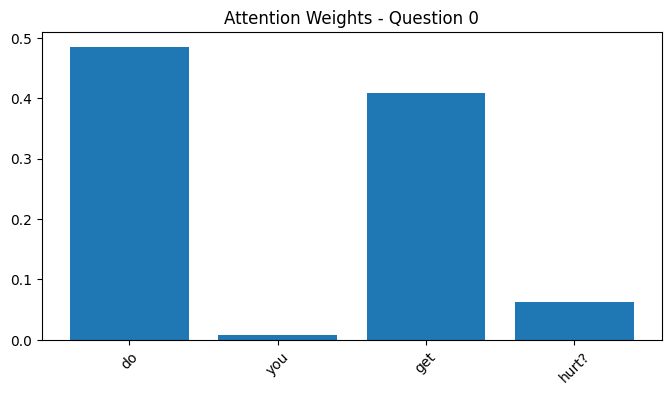

Question: do you get hurt?
Highest attention word: 'do' (0.485)



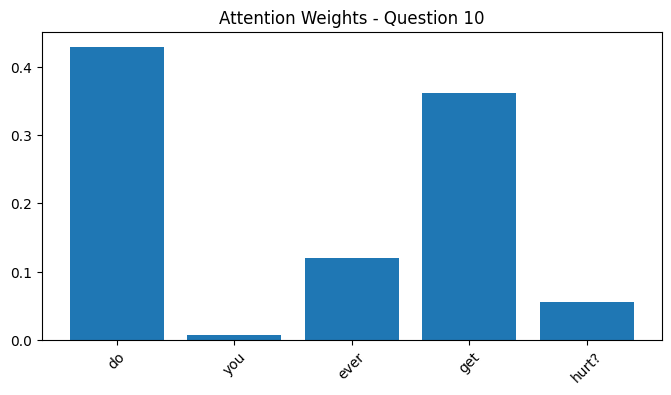

Question: do you ever get hurt?
Highest attention word: 'do' (0.430)



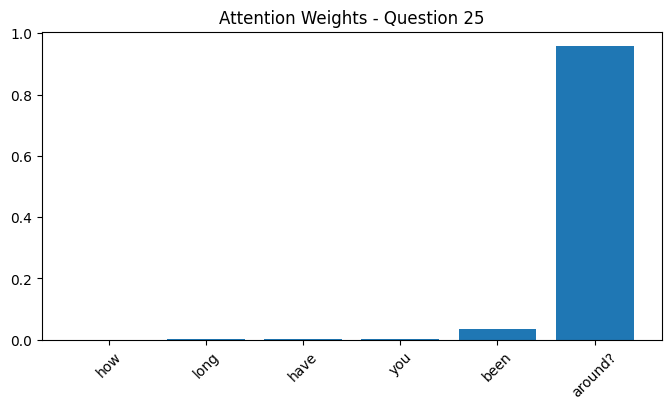

Question: how long have you been around?
Highest attention word: 'around?' (0.957)



In [9]:
def show_attention(idx):
    question = df["question"][idx]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    w = weights[0, :len(words)].tolist()

    plt.figure(figsize=(8, 4))
    plt.bar(words, w)
    plt.title(f"Attention Weights - Question {idx}")
    plt.xticks(rotation=45)
    plt.show()

    top_word = words[w.index(max(w))]
    print(f"Question: {question}")
    print(f"Highest attention word: '{top_word}' ({max(w):.3f})\n")

for i in [0, 10, 25]:
    show_attention(i)

## Task 1: Understand Attention Weights

### Observations

| Question | Highest-attention word | Weight |
|---|---|---|
| do you get hurt? | **do** | 0.485 |
| do you ever get hurt? | **do** | 0.430 |
| how long have you been around? | **around?** | 0.957 |

- **Question 0:** the highest weight went to "do" (0.485), followed by "get" (about 0.41). "hurt?" received only about 0.06 and "you" almost nothing.
- **Question 10:** again "do" received the highest weight (0.430), then "get" (about 0.36). "ever" got about 0.12 and "hurt?" about 0.05.
- **Question 25:** the model focused almost entirely on "around?" (0.957). All other words received close to zero.

### Do the highest-weighted words appear important?

Partly. In Question 25, "around" carries the core meaning of the question (it asks about age or how long the system has existed), so the focus makes sense. In Questions 0 and 10, "get" is part of the key phrase "get hurt", which is reasonable. However, "do" is a generic function word, and the most meaningful word, "hurt", received very low attention.

This suggests the model does not always focus on the words a human would consider most important. It may instead rely on patterns that help separate the answer classes, such as the opening "do" in yes/no questions, or the last word of the question, whose RNN hidden state has already accumulated information from the earlier words.

Also, attention here is applied on top of RNN hidden states, not on raw words, so a high weight on one position does not mean only that word was used. Finally, the model is small and trained for only 50 epochs, so its attention weights are not fully reliable.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

In [10]:

print(df[df["answer_id"] == 0][["question", "answer_id"]].head(10))

               question  answer_id
0      do you get hurt?          0
1  do you have fingers?          0
2   do you ever breathe          0
3     do you masticate?          0
4     can you throw up?          0
5     do you get tired?          0
6        can you crawl?          0
7          can you cry?          0
8          do you dream          0
9      do you ever pee?          0


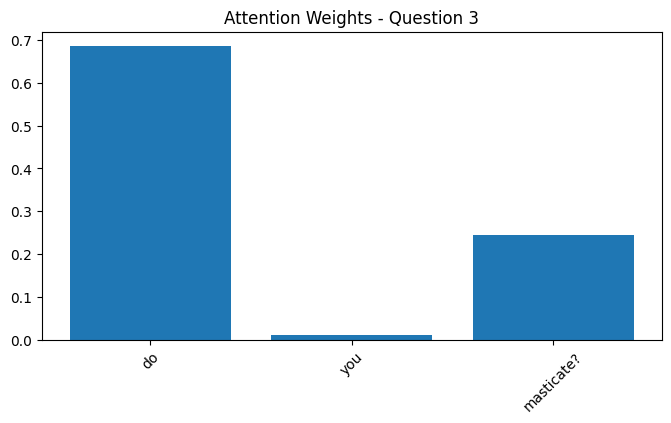

Question: do you masticate?
Highest attention word: 'do' (0.686)



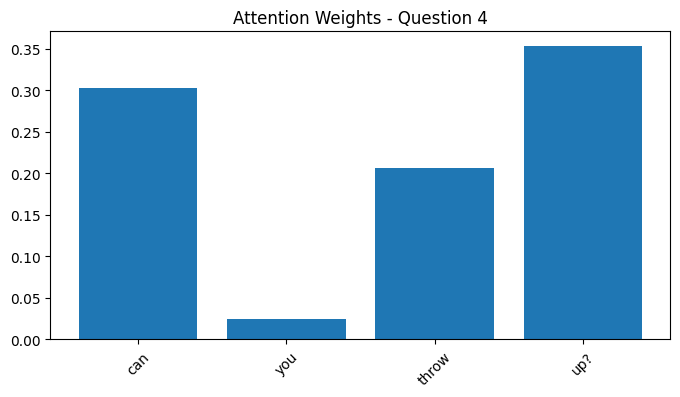

Question: can you throw up?
Highest attention word: 'up?' (0.353)

3 → predicted answer: 0 | true: 0
4 → predicted answer: 3 | true: 0


In [11]:
idx1, idx2 = 3, 4

for idx in [idx1, idx2]:
    show_attention(idx)

with torch.no_grad():
    for idx in [idx1, idx2]:
        pred, _ = model(X[idx:idx+1])
        print(idx, "→ predicted answer:", pred.argmax(1).item(),
              "| true:", y[idx].item())

## Task 2: Compare Attention for Similar Questions

### Selected questions
Both questions belong to the same answer group (answer_id = 0), so they are expected to receive the same answer.

| Question | Highest-attention word | Weight | Predicted | True |
|---|---|---|---|---|
| do you masticate? | **do** | 0.686 | 0 | 0 |
| can you throw up? | **up?** | 0.353 | 3 | 0 |

### Comparison

The model focused on **different words** for the two questions. For "do you masticate?" it put most of its attention on the opening word "do" (0.686). For "can you throw up?" the highest weight was on the last word "up?" (0.353), and this weight is much lower, which means the attention was more spread out across the sentence.

The model also predicted the correct answer for the first question but a wrong answer (3 instead of 0) for the second one.

### What this suggests about attention

Attention does not understand meaning directly. It only learns which positions help the model reduce its training loss. Two questions that have similar meaning but different wording ("do ..." vs "can ... up") can get attention on different words, because the model relies on the specific words and patterns it saw during training, not on the shared meaning.

The wrong prediction for the second question supports this: the model has not learned a general concept for this answer group, and with a small model trained for only 50 epochs, its attention is sensitive to wording. Attention weights therefore show where the model looked, but a high weight does not guarantee that the word is the most meaningful one.